### Evaluation

Notebook to run evaulation on test data

- use daily provided data (evaluation period of competition)

Data: "../data/evaluation/[met_nowcast_daily, met_forecast_daily, wind_power]"


In [ ]:
import os
import sys

sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from jax import random
from numpyro.infer import Predictive
import arviz as az

from validate_example import validate_forecast
from data_processing.load import (
    load_evaluation_data,
    load_weather_forecast_parquet,
    load_and_preprocess_forecast_data,
    rename_met_forecast_columns,
    sin_cos_transform,
    load_weather_nowcast,
    load_evaluation_forecast_data,
)
from data_processing.utils import (
    load_scaler_params,
    load_checkpoint,
    load_torch_model,
    save_scaler_params,
    QuantileDistribution,
)
from models.model import model_mw_gamma, model_cf_logitnormal, model_cf_beta
from training.evaluate import test_QR, test_BNN
import torch
import re

from configs.load_config import load_config

In [2]:
import importlib
import training.evaluate as load_eval

importlib.reload(load_eval)
from training.evaluate import test_QR, test_BNN

### Load evaluation data


In [3]:
# model_cfg = load_config("../configs/model/bnn_gen_model_nowcast.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "model_mw_gamma_2026-01-08_09-40-39_nowcast_ELSPOT_NO1"

# model_cfg = load_config("../configs/model/torch_model_quantile.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "WindPowerQuantile_2026-01-13_13-43-06_nowcast_gen_ELSPOT_NO3"

model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_04.yaml")
data_cfg = load_config(model_cfg.data.path)
file_name = "model_mw_gamma_2026-02-04_11-00-56_nowcast_ELSPOT_NO4"  # "model_mw_gamma_2026-01-15_23-33-09_nowcast_ELSPOT_NO1"  # "WindPowerModel_simple_2026-01-15_19-49-12_nowcast_gen_ELSPOT_NO3"  # "WindPowerQuantile_2026-01-14_10-25-57_nowcast_gen_ELSPOT_NO1"  # "WindPowerQuantile_2026-01-14_10-30-39_nowcast_gen_ELSPOT_NO3"

In [4]:
model_cfg

namespace(backend='numpyro',
          sampler='mcmc',
          name='model_mw_gamma',
          experiment_name='Gamma NO4',
          data=namespace(path='../configs/data/nowcast04.yaml',
                         bid_zone='ELSPOT NO4'),
          args=namespace(num_warmup=50, num_samples=50, num_chains=2),
          params=namespace(target='gen'))

In [5]:
import importlib
import data_processing.load as load_data

importlib.reload(load_data)
from data_processing.load import load_evaluation_forecast_data_eff

In [ ]:
bid_zone = model_cfg.data.bid_zone
bid_zones = ["ELSPOT NO1", "ELSPOT NO2", "ELSPOT NO3", "ELSPOT NO4"]
bid_zones = [bz.replace(" ", "_") for bz in bid_zones]


dataset = "forecast"  # data_cfg.dataset
if dataset == "nowcast":
    evaluation_dates = [
        "2025-09-22",
        "2025-09-23",
        "2025-09-24",
        "2025-09-25",
        "2025-09-26",
        "2025-09-29",
        "2025-09-30",
        # "2025-10-01",
        # "2025-10-02",
        # "2025-10-03",
    ]

    scaler_data_nowcast = load_scaler_params(
        bid_zone=bid_zone, dataset="nowcast", dir_path="../checkpoints"
    )

    eval_data = load_evaluation_data(
        dates=evaluation_dates,
        scaler_params=scaler_data_nowcast["scaler_params"],
        site_scaler_params=scaler_data_nowcast["site_scaler_params"],
        bid_zone=bid_zone,
    )

elif dataset == "forecast":
    evaluation_dates = [
        "2025-09-22",
        "2025-09-23",
        "2025-09-24",
        "2025-09-25",
        "2025-09-26",
        "2025-09-29",
        "2025-09-30",
        "2025-10-01",
        "2025-10-02",
        "2025-10-03",
    ]

    scaler_data_forecast = load_scaler_params(
        bid_zone=bid_zone, dataset="forecast", dir_path="../checkpoints"
    )

    eval_data = load_evaluation_forecast_data(
        dates=evaluation_dates,
        scaler_params=scaler_data_forecast["scaler_params"],
        site_scaler_params=scaler_data_forecast["site_scaler_params"],
        bid_zone=bid_zone,
        ensemble_members=None,
        variance_feature=False,
    )

Loaded scaler parameters for ELSPOT NO4 and forecast
  Saved at: 2026-01-13 14:46:07
  Split time: 2025-01-01 00:00:00+01:00
Loading evaluation data for 10 dates in zone ELSPOT NO4...
Loading evaluation data for 2025-09-22 in zone ELSPOT NO4
RangeIndex(start=0, stop=4087, step=1)
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-23 in zone ELSPOT NO4
RangeIndex(start=0, stop=4087, step=1)
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-24 in zone ELSPOT NO4
RangeIndex(start=0, stop=4087, step=1)
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dro

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Maintenance hours in operational period: 0
Preprocessing done. X_eval shape: (240, 13, 15, 10)
Dropped timestamps due to maintenance: 0


In [7]:
# assert np.allclose(eval_data["X_eval"], eval_data_eff["X_eval"])

### Evaluate on test set


In [8]:
import importlib
import training.evaluate as load_eval

importlib.reload(load_eval)
from training.evaluate import test_QR, test_BNN

In [9]:
eval_data["X_eval"].shape

(240, 13, 15, 10)

In [10]:
eval_data["X_eval"][0, 0, :, 1]

array([0.40355936, 0.3555787 , 0.36837426, 0.40057817, 0.34088573,
       0.31192878, 0.2913513 , 0.27938765, 0.4084021 , 0.38881618,
       0.23289497, 0.3279283 , 0.3197017 , 0.4122481 , 0.3174644 ],
      dtype=float32)

In [11]:
import importlib
import training.evaluate as load_eval

importlib.reload(load_eval)
from training.evaluate import test_QR, test_BNN

In [12]:
forecasts_ext = []
for member in range(15):

    if model_cfg.backend == "numpyro":

        forecast, forecast_extended, bz_from_checkpoint = test_BNN(
            file_name, eval_data, member=member
        )

    elif model_cfg.backend == "torch":

        forecast, forecast_extended, bz_from_checkpoint = test_QR(
            file_name,
            eval_data,
            ensembles=False,
            from_now_to_forecast=True,
            member=member,
        )

    forecasts_ext.append(forecast_extended[int(bz_from_checkpoint[-1]) - 1])

Choose ensemble member 0
Loading specified checkpoint: ../checkpoints/model_mw_gamma_2026-02-04_11-00-56_nowcast_ELSPOT_NO4.pkl
Choose ensemble member 1
Loading specified checkpoint: ../checkpoints/model_mw_gamma_2026-02-04_11-00-56_nowcast_ELSPOT_NO4.pkl
Choose ensemble member 2
Loading specified checkpoint: ../checkpoints/model_mw_gamma_2026-02-04_11-00-56_nowcast_ELSPOT_NO4.pkl
Choose ensemble member 3
Loading specified checkpoint: ../checkpoints/model_mw_gamma_2026-02-04_11-00-56_nowcast_ELSPOT_NO4.pkl
Choose ensemble member 4
Loading specified checkpoint: ../checkpoints/model_mw_gamma_2026-02-04_11-00-56_nowcast_ELSPOT_NO4.pkl
Choose ensemble member 5
Loading specified checkpoint: ../checkpoints/model_mw_gamma_2026-02-04_11-00-56_nowcast_ELSPOT_NO4.pkl
Choose ensemble member 6
Loading specified checkpoint: ../checkpoints/model_mw_gamma_2026-02-04_11-00-56_nowcast_ELSPOT_NO4.pkl
Choose ensemble member 7
Loading specified checkpoint: ../checkpoints/model_mw_gamma_2026-02-04_11-00-56

In [13]:
df_out = pd.concat(forecasts_ext, axis=1, keys=range(len(forecasts_ext)))

df_out.columns = [f"{col}_{i}" for i, col in df_out.columns]

median_cols = df_out.filter(regex=r"^median_").columns
hdi_lower_cols = df_out.filter(regex=r"^hdi_lower_").columns
hdi_upper_cols = df_out.filter(regex=r"^hdi_upper_").columns

df_out["mean_median"] = df_out[median_cols].mean(axis=1)
df_out["std_median"] = df_out[median_cols].std(axis=1)
df_out["mean_hdi_lower"] = df_out[hdi_lower_cols].mean(axis=1)
df_out["std_hdi_lower"] = df_out[hdi_lower_cols].std(axis=1)
df_out["mean_hdi_upper"] = df_out[hdi_upper_cols].mean(axis=1)
df_out["std_hdi_upper"] = df_out[hdi_upper_cols].std(axis=1)

In [14]:
df_out

,median_0,hdi_lower_0,hdi_upper_0,median_1,hdi_lower_1,hdi_upper_1,median_2,hdi_lower_2,hdi_upper_2,median_3,...,hdi_upper_13,median_14,hdi_lower_14,hdi_upper_14,mean_median,std_median,mean_hdi_lower,std_hdi_lower,mean_hdi_upper,std_hdi_upper
2025-09-24 00:00:00+02:00,184.144180,4.395805e-08,481.054962,185.320068,1.400384e-15,490.834229,187.632477,5.183617e-09,475.014374,193.213593,...,423.470032,182.360657,0.000305,432.047882,179.797593,15.597524,0.001893,0.006726,442.754606,30.131839
2025-09-24 01:00:00+02:00,201.906921,4.674396e-13,432.517883,209.936310,2.978878e-21,456.175812,208.256973,2.758962e-10,456.636627,218.438751,...,519.287537,188.630478,0.000100,526.069702,190.243952,22.999527,0.000731,0.002804,460.355747,53.659038
2025-09-24 02:00:00+02:00,184.676849,2.280227e-15,444.448944,200.215973,0.000000e+00,450.507751,194.662598,9.749404e-13,448.577087,206.644714,...,437.670990,160.961197,0.000025,415.823090,171.736089,21.813650,0.000784,0.003028,418.265336,37.590845
2025-09-24 03:00:00+02:00,171.962158,2.961847e-09,419.778107,169.339355,5.430636e-13,380.674255,163.284698,4.365302e-07,390.209930,192.702118,...,357.435181,166.265305,0.000882,342.136383,158.249033,18.983267,0.000229,0.000668,373.039010,33.016877
2025-09-24 04:00:00+02:00,176.493073,1.316217e-05,382.512482,224.310760,1.165125e-10,441.839264,166.434631,9.624971e-04,357.214905,217.099869,...,344.667694,185.977417,0.002511,373.857605,170.606375,28.572333,0.031703,0.107039,369.886997,36.593822
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-10-05 19:00:00+02:00,519.003357,0.000000e+00,1048.197266,530.051270,0.000000e+00,1021.564575,516.313110,0.000000e+00,1027.910522,490.026306,...,1124.133911,582.997803,0.000000,1144.810303,543.159123,57.918211,0.000000,0.000000,1065.150895,97.660459
2025-10-05 20:00:00+02:00,480.605591,0.000000e+00,950.252930,523.141907,0.000000e+00,999.068665,480.516052,0.000000e+00,906.061157,512.322144,...,1004.381470,600.127686,0.000000,1049.246826,525.842289,58.677389,0.000000,0.000000,991.111125,70.199556
2025-10-05 21:00:00+02:00,304.763885,0.000000e+00,925.585938,268.944580,0.000000e+00,963.119446,250.440552,0.000000e+00,893.923340,264.919769,...,995.409424,310.529419,0.000000,1077.368042,281.452989,19.153369,0.000000,0.000000,957.714677,84.421318
2025-10-05 22:00:00+02:00,200.152634,0.000000e+00,828.677002,205.120407,0.000000e+00,878.343689,199.870758,0.000000e+00,828.761475,179.720078,...,835.651123,231.992569,0.000000,930.624207,224.468068,47.509539,0.000000,0.000000,855.110616,83.347888


In [15]:
# # Save predictions to CSV
# data_folder = f"../data/evaluation/eval_period"
# file_path = f"{data_folder}/forecast.csv"
# if not os.path.exists(data_folder):
#     os.makedirs(data_folder)
# forecast.to_csv(file_path)

In [16]:
# # Validate format
# df = validate_forecast(file_path)

### Metrics


In [17]:
bid_zone = model_cfg.data.bid_zone.replace(" ", "_")
i = int(bid_zone.split("NO")[-1]) - 1
print(i, bid_zone)

rmse = np.sqrt(np.mean((forecast[bid_zone] - eval_data["Y_eval_gen"]) ** 2))

print("Test RMSE (gen prediction):", rmse)
inside = (eval_data["Y_eval_gen"] >= forecast_extended[i]["hdi_lower"]) & (
    eval_data["Y_eval_gen"] <= forecast_extended[i]["hdi_upper"]
)
coverage_90 = inside.mean()
print(f"\nEmpirical coverage (0.025–0.975): {coverage_90:.3f}")

below_median = (eval_data["Y_eval_gen"] <= forecast_extended[i]["median"]).mean()
print(f"Below median (should be ~0.5): {below_median:.3f}")

3 ELSPOT_NO4
Test RMSE (gen prediction): 263.233

Empirical coverage (0.025–0.975): 0.858
Below median (should be ~0.5): 0.037


### Plot prediction


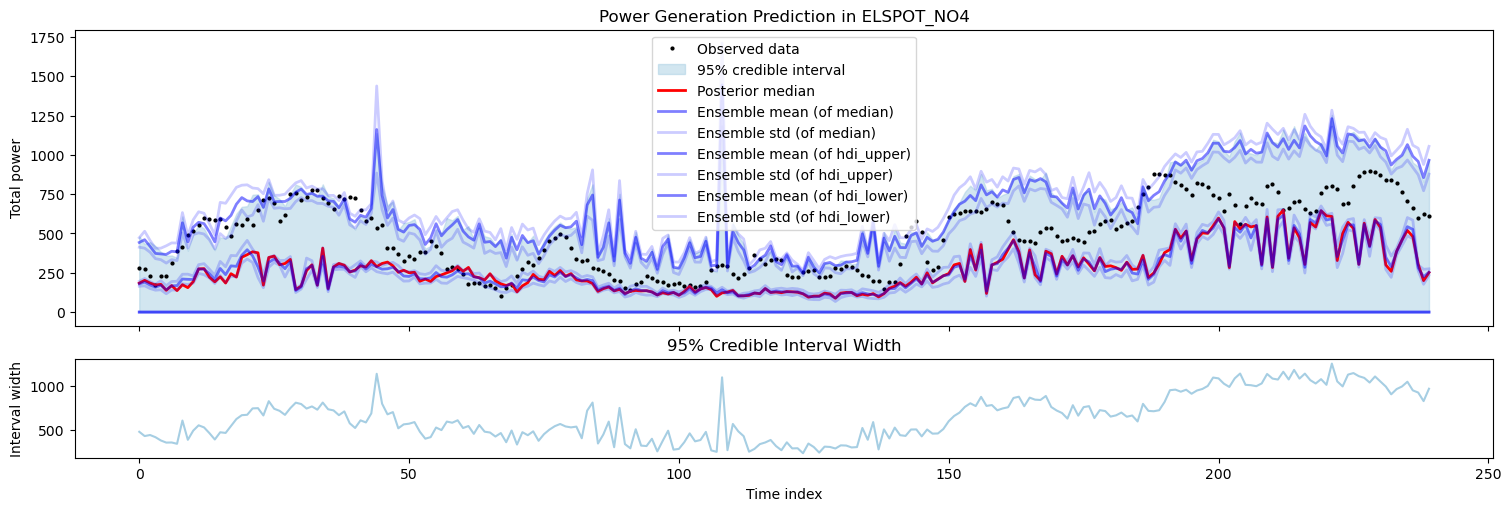

In [18]:
fig, axes = plt.subplots(
    nrows=2,
    figsize=(15, 5),
    sharex=True,
    constrained_layout=True,
    gridspec_kw={"height_ratios": [3, 1]},
)

ax = axes[0]
ax.plot(
    eval_data["Y_eval_gen"],
    ".",
    color="black",
    label="Observed data",
    markersize=4,
)

ax.fill_between(
    np.arange(len(df_out.index)),
    df_out["hdi_lower_0"].values,
    df_out["hdi_upper_0"].values,
    color="#A6CEE3",
    alpha=0.5,
    label="95% credible interval",
)

ax.plot(
    df_out["median_0"].values,
    color="red",
    label="Posterior median",
    lw=2,
)

ax.set(
    ylabel="Total power",
    title=f"Power Generation Prediction in {bid_zone}",
)


# Compute interval width
width = df_out["hdi_upper_0"].values - df_out["hdi_lower_0"].values
ax2 = axes[1]
ax2.plot(width, color="#A6CEE3")
ax2.set(
    xlabel="Time index",
    ylabel="Interval width",
    title="95% Credible Interval Width",
)

keys = ["median", "hdi_upper", "hdi_lower"]
colors = ["blue", "blue", "blue"]

for c, k in zip(colors, keys):
    # Ensemble mean of median
    ax.plot(
        df_out["mean_" + k].values,
        color=c,
        lw=2,
        alpha=0.5,
        linestyle="-",
        label=f"Ensemble mean (of {k})",
    )
    # Ensemble mean of median
    ax.plot(
        df_out["mean_" + k].values + df_out["std_" + k].values,
        color=c,
        lw=2,
        alpha=0.2,
        linestyle="-",
        # label=f"Ensemble std (of {k})",
    )
    # Ensemble mean of median
    ax.plot(
        df_out["mean_" + k].values - df_out["std_" + k].values,
        color=c,
        lw=2,
        alpha=0.2,
        linestyle="-",
        label=f"Ensemble std (of {k})",
    )
ax.legend()

plt.show()

In [19]:
# # First, load nowcast data (or load existing scaler params)
# nowcast_data = load_and_preprocess_data(bid_zone="ELSPOT NO1")

In [20]:
# # Now load forecast data using the SAME scaler parameters

# forecast_data = load_and_preprocess_forecast_data(
#     scaler_params=None,
#     site_scaler_params=None,
#     bid_zone="ELSPOT NO1",
#     ensemble_member=0,  # Use member 0
#     data_path="../data",
# )

In [21]:
# # Plot cf vs gen model for QR
# fig, axes = plt.subplots(nrows=2, figsize=(10, 7), sharex=True, constrained_layout=True)

# ax = axes[0]
# ax.plot(
#     eval_data["Y_eval_gen"],
#     ".",
#     color="black",
#     label="Observed data",
#     markersize=4,
# )

# # file_name = "WindPowerQuantile_2025-12-02_11-34-46_fore_ELSPOT_NO1"
# # file_name="WindPowerModel_simple_2025-12-02_11-11-30_fore_ELSPOT_NO1"
# # file_name = "WindPowerQuantile_2025-12-03_14-57-43_now_gen_ELSPOT_NO1"
# file_name = "WindPowerQuantile_2025-12-04_12-21-40_now_gen_ELSPOT_NO1"
# # file_name = "WindPowerQuantile_2025-12-03_14-54-34_now_cf_ELSPOT_NO1"
# # file_name = "WindPowerModel_simple_2025-12-01_10-31-55_ELSPOT_NO1"

# forecast, forecast_extended = evaluate_QR(file_name)

# ax.fill_between(
#     np.arange(24 * len(evaluation_dates)),
#     forecast_extended[i]["hdi_lower"].values,
#     forecast_extended[i]["hdi_upper"].values,
#     color="#A6CEE3",
#     alpha=0.5,
#     label="95% credible interval",
# )

# ax.plot(
#     forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
# )

# ax.set(
#     ylabel="Total power",
#     title=f"QR Power Generation Prediction in {bid_zone}",
# )
# ax.legend(fontsize=14)
# ax.title.set_fontsize(18)
# ax.xaxis.label.set_size(16)
# ax.yaxis.label.set_size(16)


# ax = axes[1]
# ax.plot(
#     eval_data["Y_eval_gen"],
#     ".",
#     color="black",
#     label="Observed data",
#     markersize=4,
# )
# # file_name = "WindPowerQuantile_2025-12-02_11-34-46_fore_ELSPOT_NO1"
# # file_name="WindPowerModel_simple_2025-12-02_11-11-30_fore_ELSPOT_NO1"
# # file_name = "WindPowerQuantile_2025-12-03_14-57-43_now_gen_ELSPOT_NO1"
# file_name = "WindPowerQuantile_2025-12-03_14-54-34_now_cf_ELSPOT_NO1"
# # file_name = "WindPowerModel_simple_2025-12-01_10-31-55_ELSPOT_NO1"

# forecast, forecast_extended = evaluate_QR(file_name)

# ax.fill_between(
#     np.arange(24 * len(evaluation_dates)),
#     forecast_extended[i]["hdi_lower"].values,
#     forecast_extended[i]["hdi_upper"].values,
#     color="#A6CEE3",
#     alpha=0.5,
#     label="95% credible interval",
# )

# ax.plot(
#     forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
# )

# ax.set(
#     xlabel="Time Index (Forecast test period)",
#     ylabel="Total power",
#     title=f"QR Capacity Factor Prediction in {bid_zone}",
# )
# ax.title.set_fontsize(18)
# ax.xaxis.label.set_size(16)
# ax.yaxis.label.set_size(16)

# plt.show()

In [22]:
# # Plot cf vs gen model for BNN
# fig, axes = plt.subplots(nrows=2, figsize=(10, 7), sharex=True, constrained_layout=True)

# ax = axes[0]
# ax.plot(
#     eval_data["Y_eval_gen"],
#     ".",
#     color="black",
#     label="Observed data",
#     markersize=4,
# )

# file_name = "model_mw_gamma_2025-11-21_10-30-46_gen_ELSPOT_NO1"
# forecast, forecast_extended = evaluate_BNN(file_name)

# ax.fill_between(
#     np.arange(24 * len(evaluation_dates)),
#     forecast_extended[i]["hdi_lower"].values,
#     forecast_extended[i]["hdi_upper"].values,
#     color="#A6CEE3",
#     alpha=0.5,
#     label="95% credible interval",
# )

# ax.plot(
#     forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
# )

# ax.set(
#     ylabel="Total power",
#     title=f"BNN Power Generation Prediction (Gamma) in {bid_zone}",
# )
# ax.legend(fontsize=14)
# ax.title.set_fontsize(18)
# ax.xaxis.label.set_size(16)
# ax.yaxis.label.set_size(16)


# ax = axes[1]
# ax.plot(
#     eval_data["Y_eval_gen"],
#     ".",
#     color="black",
#     label="Observed data",
#     markersize=4,
# )
# file_name = "model_cf_beta_2025-12-01_10-03-45_cf_ELSPOT_NO1"

# forecast, forecast_extended = evaluate_BNN(file_name)

# ax.fill_between(
#     np.arange(24 * len(evaluation_dates)),
#     forecast_extended[i]["hdi_lower"].values,
#     forecast_extended[i]["hdi_upper"].values,
#     color="#A6CEE3",
#     alpha=0.5,
#     label="95% credible interval",
# )

# ax.plot(
#     forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
# )

# ax.set(
#     xlabel="Time Index (Forecast test period)",
#     ylabel="Total power",
#     title=f"BNN Capacity Factor Prediction (Beta) in {bid_zone}",
# )
# ax.title.set_fontsize(18)
# ax.xaxis.label.set_size(16)
# ax.yaxis.label.set_size(16)

# plt.show()